In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set styling for research plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Define paths
BASE_DIR = Path("..")
PROCESSED_DIR = BASE_DIR / "data" / "processed"
TICKERS = ["SPY", "QQQ", "IWM", "TLT", "GLD"]

# Load the processed data into a dictionary
data = {}
for ticker in TICKERS:
    filepath = PROCESSED_DIR / f"{ticker}_processed.csv"
    data[ticker] = pd.read_csv(filepath, index_col='Date', parse_dates=True)
    print(f"Loaded {ticker}: {data[ticker].shape} rows")

Loaded SPY: (2515, 7) rows
Loaded QQQ: (2515, 7) rows
Loaded IWM: (2515, 7) rows
Loaded TLT: (2515, 7) rows
Loaded GLD: (2515, 7) rows


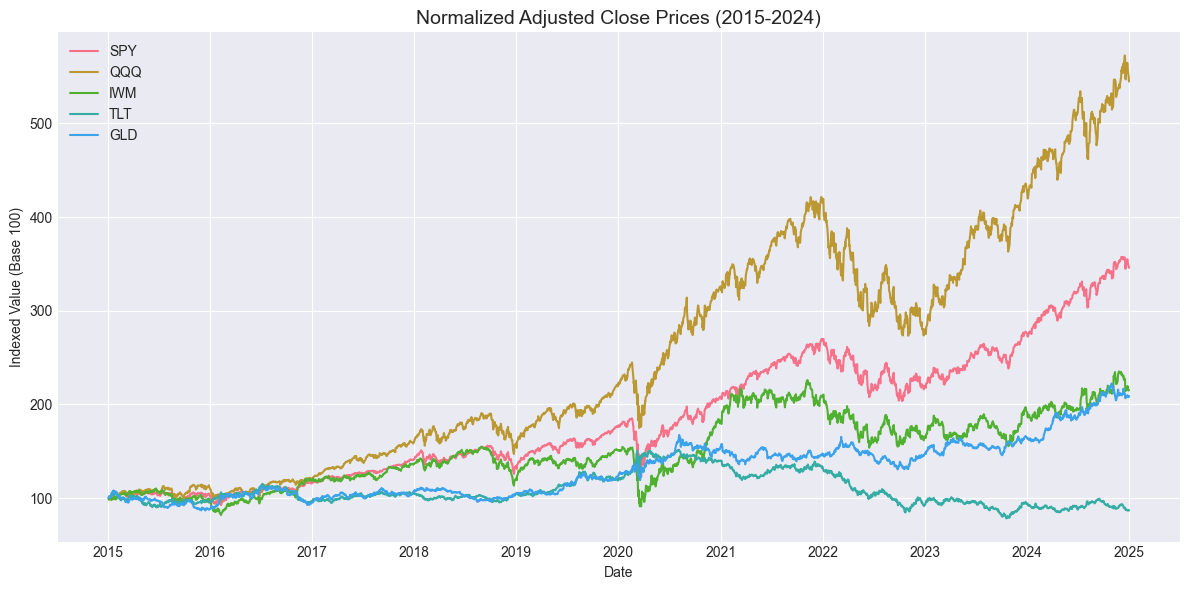

In [2]:
fig, ax = plt.subplots(figsize=(12, 6))

for ticker in TICKERS:
    # Normalize prices to start at 100 for fair comparison
    normalized = (data[ticker]['Adj Close'] / data[ticker]['Adj Close'].iloc[0]) * 100
    ax.plot(normalized, label=ticker, linewidth=1.5)

ax.set_title("Normalized Adjusted Close Prices (2015-2024)", fontsize=14)
ax.set_ylabel("Indexed Value (Base 100)")
ax.set_xlabel("Date")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

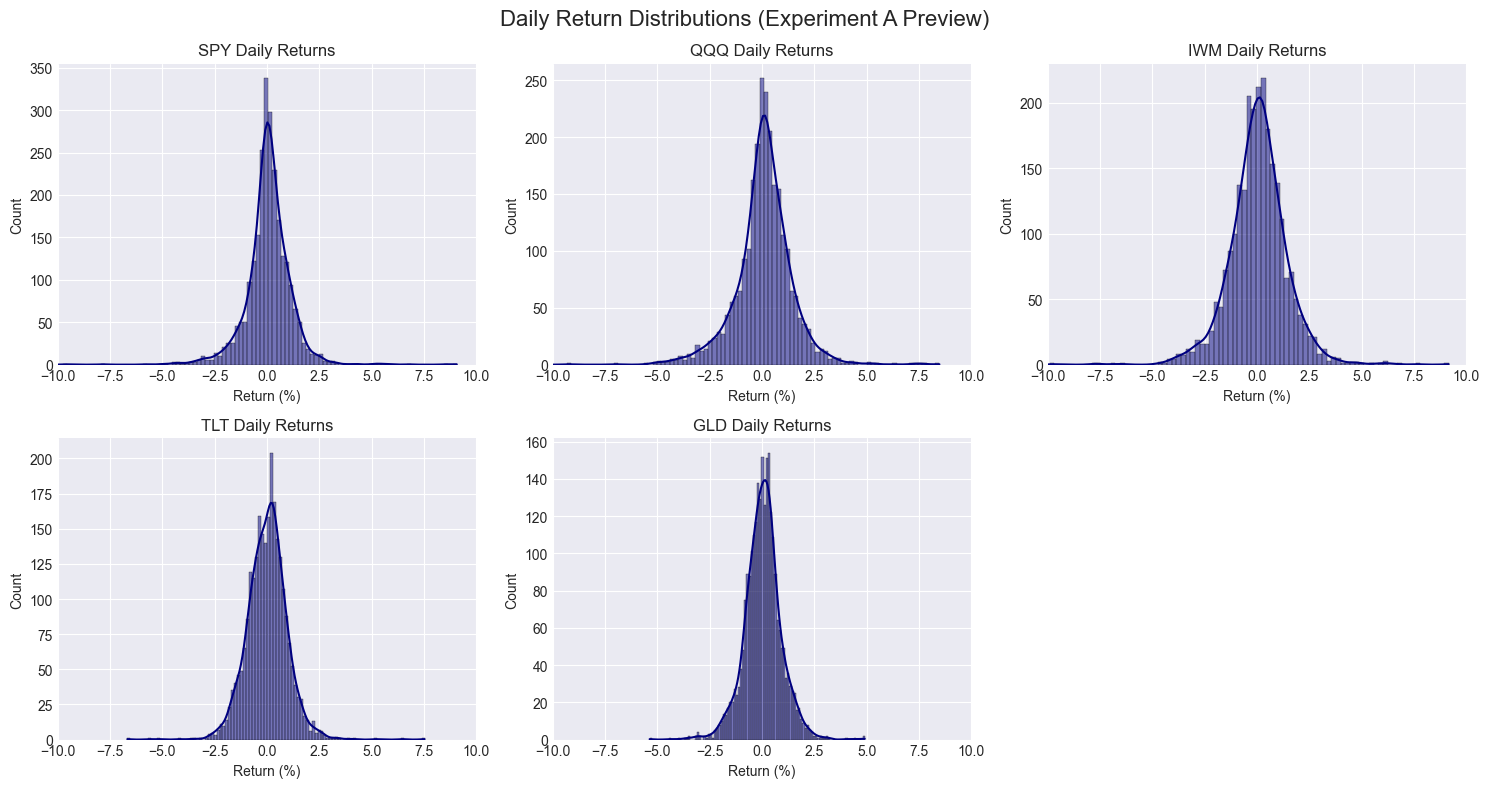

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, ticker in enumerate(TICKERS):
    returns = data[ticker]['Daily_Return'] * 100 # Convert to percentage
    sns.histplot(returns, bins=100, kde=True, ax=axes[i], color='navy')
    axes[i].set_title(f"{ticker} Daily Returns")
    axes[i].set_xlabel("Return (%)")
    axes[i].set_xlim(-10, 10) # Zoom in to see the distribution shape

# Hide the empty 6th subplot
axes[5].axis('off')

plt.suptitle("Daily Return Distributions (Experiment A Preview)", fontsize=16)
plt.tight_layout()
plt.show()

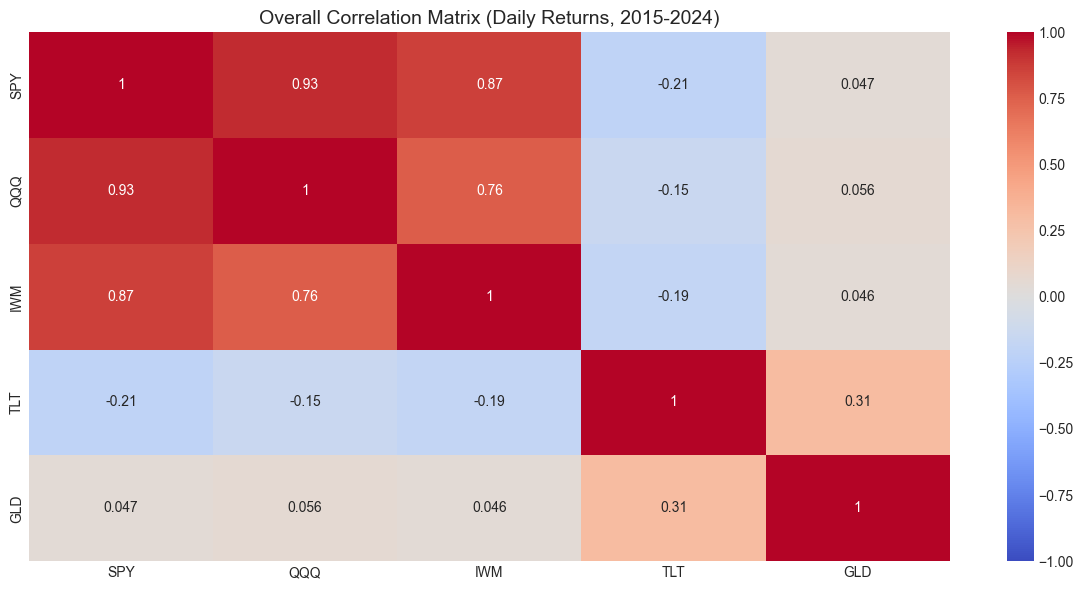

In [4]:
# Create a combined DataFrame of daily returns
returns_df = pd.DataFrame({ticker: data[ticker]['Daily_Return'] for ticker in TICKERS})

# Compute the 252-day (1 trading year) rolling correlation for SPY vs TLT vs GLD
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(returns_df.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Overall Correlation Matrix (Daily Returns, 2015-2024)", fontsize=14)
plt.tight_layout()
plt.show()

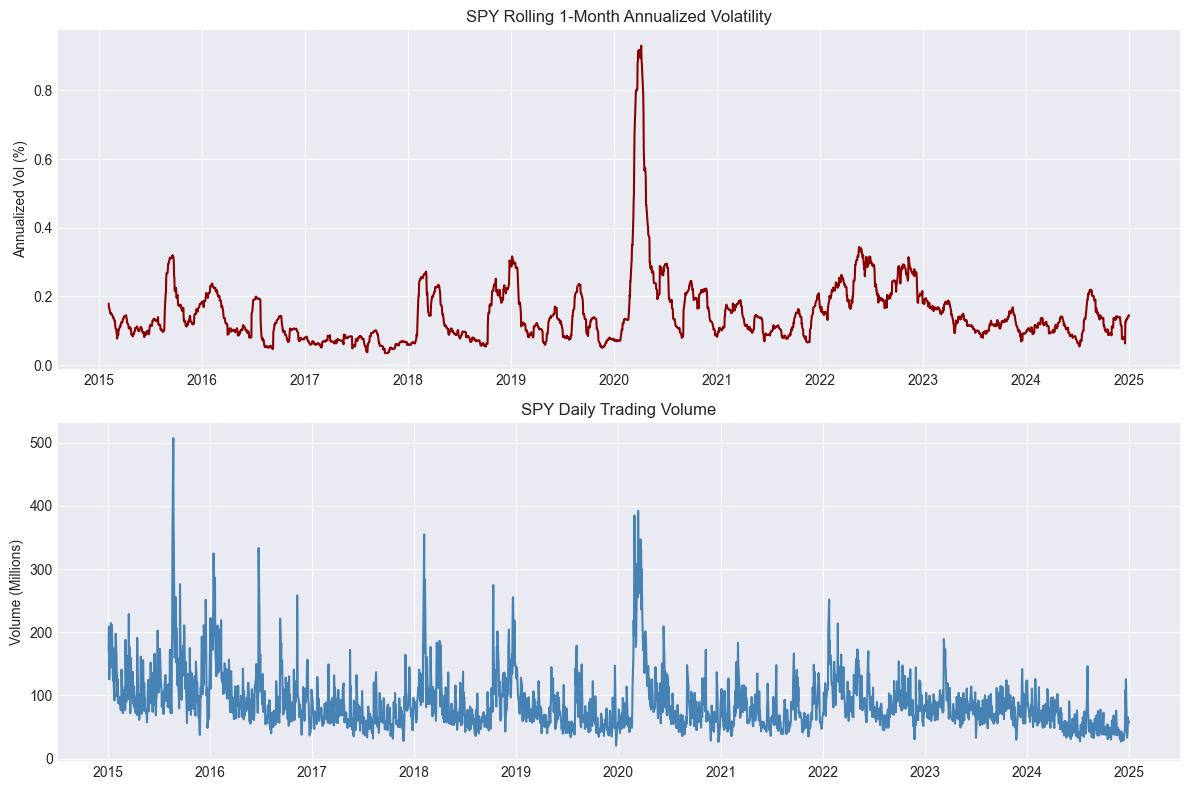

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Rolling 21-day (1 month) volatility for SPY
spy_vol = data['SPY']['Daily_Return'].rolling(window=21).std() * np.sqrt(252) # Annualized
axes[0].plot(spy_vol, color='darkred')
axes[0].set_title("SPY Rolling 1-Month Annualized Volatility")
axes[0].set_ylabel("Annualized Vol (%)")

# SPY Volume
axes[1].plot(data['SPY']['Volume'] / 1e6, color='steelblue') # Millions
axes[1].set_title("SPY Daily Trading Volume")
axes[1].set_ylabel("Volume (Millions)")

plt.tight_layout()
plt.show()